# Murfreesboro PD — Flock Search Trend Analysis
Trend analysis of Murfreesboro PD Flock ALPR searches, using the categorized output from `norm_template.ipynb`.

**Input:** `./categorized_output/Murfreesboro_categorized.csv` (one row per search record, with `reason_category` already assigned)

**What this notebook covers**
1. Data cleaning: duplicate search records and timezone conversion
2. Data coverage: which months are actually usable
3. Search volume over time
4. Category mix over time (how the reasons officers give are shifting)
5. When searches happen (hour × weekday)
6. Search scope (time window and number of cameras searched)
7. User accounts and case-number-only reasons
8. Reason vocabulary
9. Exports + findings

> **Read before interpreting:** these records come from *other agencies'* network audits that happen to include Murfreesboro's searches of their cameras. Monthly **volume** therefore reflects which audits were obtained as much as how often MPD searched. Category **shares** (percent of a month's searches) are much more robust to that, so the trend sections lean on shares.

In [1]:
import json
import re
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

DATA_PATH  = "./categorized_output/Murfreesboro_categorized.csv"
OUT_DIR    = "./analysis_output/murfreesboro"
LOCAL_TZ   = "America/Chicago"          # Murfreesboro is in Central time
WINDOW     = ("2024-01", "2025-12")     # analysis window, justified in Section 2

os.makedirs(OUT_DIR, exist_ok=True)

# Chart styling: thin marks, recessive grid, one accent colour
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False, "legend.fontsize": 8,
})
pd.set_option("display.max_columns", 40, "display.width", 160)

## 1. Load and clean

In [2]:
raw = pd.read_csv(DATA_PATH, dtype=str)
print(f"Raw rows: {len(raw):,}")

for col in ["search_time_utc", "start_timeframe_utc", "end_timeframe_utc"]:
    raw[col.replace("_utc", "")] = pd.to_datetime(raw[col], utc=True, errors="coerce").dt.tz_convert(LOCAL_TZ)
for col in ["total_devices_searched", "total_networks_searched"]:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")
raw.loc[raw["total_devices_searched"] == 0, "total_devices_searched"] = np.nan   # 0 = redacted in some audits

raw = raw.dropna(subset=["search_time"])
raw[["search_time", "name", "reason", "reason_category"]].head()

Raw rows: 47,501


,search_time,name,reason,reason_category
0,2024-11-21 08:13:25-06:00,D. Joh,MPPAT-24-0108593,No Offense Stated / Redacted
1,2025-03-11 16:05:46-05:00,M. Hic,MPPAT-25-0020851,No Offense Stated / Redacted
2,2025-04-21 13:21:39-05:00,D. Joh,ATL - 53s,BOLO / Suspect Vehicle
3,2025-06-10 10:05:38-05:00,M. Hic,25-10867,No Offense Stated / Redacted
4,2025-03-03 08:12:35-06:00,M. Hic,25-0003907,No Offense Stated / Redacted


### 1a. Duplicate searches
The same search can show up in several source audits (e.g. once in a Texas audit and again in a Georgia audit), each with its own `id` and with different fields redacted. Rows that share the exact search timestamp, reason, and searched time window are the same search, so we keep **one** copy, preferring the copy with the most non-redacted detail.

In [3]:
KEY = ["search_time_utc", "reason", "start_timeframe_utc", "end_timeframe_utc"]

dupe_mask = raw.duplicated(KEY, keep=False)
print(f"Rows involved in duplication: {dupe_mask.sum():,}")

detail_cols = ["name", "license_plate_hash", "search_type", "total_devices_searched", "case_number"]
raw["_detail"] = raw[detail_cols].notna().sum(axis=1)
raw["_n_sources"] = raw["sources"].apply(lambda s: len(json.loads(s)) if isinstance(s, str) else 0)

df = (raw.sort_values("_detail", ascending=False)
         .drop_duplicates(KEY, keep="first")
         .sort_values("search_time")
         .reset_index(drop=True))

print(f"Unique searches: {len(df):,}  (removed {len(raw) - len(df):,} duplicates = {1 - len(df)/len(raw):.1%} of raw rows)")

Rows involved in duplication: 30,948
Unique searches: 28,183  (removed 19,317 duplicates = 40.7% of raw rows)


**Note for the group:** the cross-city pivot in `norm_template.ipynb` counts raw rows, so it is inflated by these duplicates. The other cities' files probably need the same dedup step before cities are compared.

### 1b. Derived fields

In [4]:
df["month"]   = df["search_time"].dt.tz_localize(None).dt.to_period("M")
df["date"]    = df["search_time"].dt.date
df["hour"]    = df["search_time"].dt.hour
df["weekday"] = df["search_time"].dt.day_name()
df["window_hours"] = (df["end_timeframe"] - df["start_timeframe"]).dt.total_seconds() / 3600

# Some source audits (mainly Dunwoody GA) drop the reason field entirely. Those rows are a
# collection artifact, not an officer leaving the field blank, so they are separated out.
df["reason_recorded"] = df["reason"].fillna("").str.strip().ne("")
df.loc[~df["reason_recorded"], "reason_category"] = "Reason Not In Source Audit"

NON_OFFENSE = {"No Offense Stated / Redacted", "Malformed / Unintelligible", "Misc / Other", "Routine / Administrative / Test"}
df["has_offense"] = ~df["reason_category"].isin(NON_OFFENSE)

print(f"Searches whose source audit omitted the reason: {(~df['reason_recorded']).sum():,} ({(~df['reason_recorded']).mean():.1%})")
df[["search_time", "month", "hour", "weekday", "window_hours", "reason_category", "has_offense"]].head()

Searches whose source audit omitted the reason: 2,400 (8.5%)


,search_time,month,hour,weekday,window_hours,reason_category,has_offense
0,2023-10-03 13:38:21-05:00,2023-10,13,Tuesday,720.0,No Offense Stated / Redacted,False
1,2023-10-04 13:06:29-05:00,2023-10,13,Wednesday,720.0,BOLO / Suspect Vehicle,True
2,2023-10-05 13:43:04-05:00,2023-10,13,Thursday,720.0,No Offense Stated / Redacted,False
3,2023-10-05 13:46:56-05:00,2023-10,13,Thursday,720.0,No Offense Stated / Redacted,False
4,2023-10-05 13:52:14-05:00,2023-10,13,Thursday,720.0,No Offense Stated / Redacted,False


## 2. Data coverage: which months can we trust?
The number of searches per month and the number of distinct source audit files covering each month are plotted separately. When the two move together, swings in volume come from **coverage**, not from MPD behaviour.

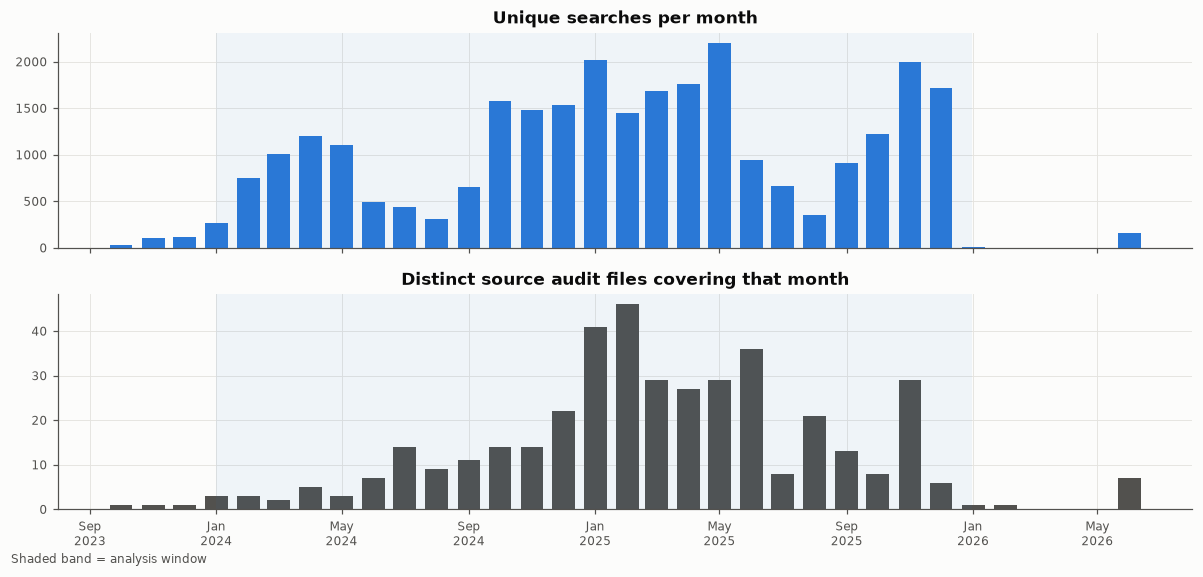

Correlation between monthly searches and # source audits: r = 0.66

Months outside the window:
            searches  source_audits
month                              
2023-10-01        34              1
2023-11-01       109              1
2023-12-01       115              1
2026-01-01         8              1
2026-02-01         1              1
2026-06-01       163              7


In [5]:
def source_ids(s):
    try:
        return [x["id"] for x in json.loads(s)]
    except Exception:
        return []

src = (raw.assign(src=raw["sources"].apply(source_ids),
                  month=raw["search_time"].dt.tz_localize(None).dt.to_period("M"))
          .explode("src").groupby("month")["src"].nunique())

coverage = pd.DataFrame({"searches": df.groupby("month").size(), "source_audits": src}).fillna(0).astype(int)
coverage.index = coverage.index.to_timestamp()

fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
axes[0].bar(coverage.index, coverage["searches"], width=22, color=BLUE)
axes[0].set_title("Unique searches per month")
axes[1].bar(coverage.index, coverage["source_audits"], width=22, color=INK2)
axes[1].set_title("Distinct source audit files covering that month")
for ax in axes:
    ax.axvspan(pd.Timestamp(WINDOW[0]), pd.Timestamp(WINDOW[1]) + pd.offsets.MonthEnd(0), color=BLUE, alpha=0.06, lw=0)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.text(0.01, 0.005, "Shaded band = analysis window", fontsize=8, color=INK2)
plt.tight_layout(); plt.show()

r = coverage[["searches", "source_audits"]].corr().iloc[0, 1]
print(f"Correlation between monthly searches and # source audits: r = {r:.2f}")
print("\nMonths outside the window:")
print(coverage[(coverage.index < WINDOW[0]) | (coverage.index > pd.Timestamp(WINDOW[1]))])

Separately, some audits omit the `reason` column. The worst case is **Sep 2025**, where the only source is a Dunwoody GA audit with no reasons. Reason-based sections use only searches with a recorded reason, and months with fewer than 100 such searches are masked.

Late 2023 and 2026 are sparse (2026 has almost nothing until a small June batch), so the rest of the notebook uses **Jan 2024 – Dec 2025**. Even inside that window, volume is partly driven by coverage, so treat Section 3 as descriptive and lean on the share-based trends in Section 4.

In [6]:
w = df[(df["month"] >= pd.Period(WINDOW[0])) & (df["month"] <= pd.Period(WINDOW[1]))].copy()
months = pd.period_range(WINDOW[0], WINDOW[1], freq="M")
wr = w[w["reason_recorded"]].copy()        # used for every reason-based analysis
MIN_N = 100                                 # months with fewer recorded reasons than this are masked in share plots
n_rec = wr.groupby("month").size().reindex(months, fill_value=0)
print(f"Searches in window: {len(w):,} of {len(df):,}")
print(f"  with a recorded reason: {len(wr):,}")
print(f"  months masked in share plots (<{MIN_N} recorded reasons): {[str(m) for m in n_rec[n_rec < MIN_N].index]}")

Searches in window: 27,753 of 28,183
  with a recorded reason: 25,361
  months masked in share plots (<100 recorded reasons): ['2025-09']


## 3. Search volume over time

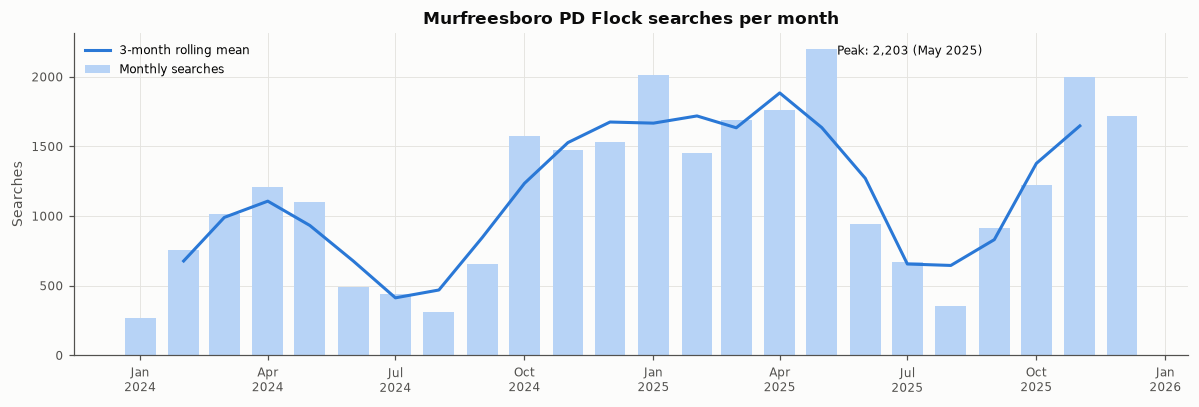

search_time
2024    10815
2025    16938

2025 vs 2024: +56.6%


In [7]:
monthly = w.groupby("month").size().reindex(months, fill_value=0)
mt = monthly.copy(); mt.index = mt.index.to_timestamp()
roll = mt.rolling(3, center=True).mean()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(mt.index, mt.values, width=22, color="#b7d3f6", label="Monthly searches")
ax.plot(roll.index, roll.values, color=BLUE, label="3-month rolling mean")
ax.set_title("Murfreesboro PD Flock searches per month")
ax.set_ylabel("Searches")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.legend(loc="upper left")
pk = mt.idxmax()
ax.annotate(f"Peak: {mt.max():,} ({pk:%b %Y})", (pk, mt.max()), xytext=(10, -4),
            textcoords="offset points", fontsize=8, color=INK)
plt.tight_layout(); plt.show()

yearly = w.groupby(w["search_time"].dt.year).size()
print(yearly.to_string())
print(f"\n2025 vs 2024: {yearly.loc[2025] / yearly.loc[2024] - 1:+.1%}")

## 4. Category mix over time
### 4a. Overall mix (deduplicated, in window)

In [8]:
cat_tot = wr["reason_category"].value_counts()
cat_tbl = pd.DataFrame({"searches": cat_tot, "share": (cat_tot / len(wr)).round(4)})
cat_tbl

,searches,share
reason_category,,
No Offense Stated / Redacted,17009,0.6707
BOLO / Suspect Vehicle,2322,0.0916
General Investigation,1765,0.0696
Violent / Sexual Crime,1354,0.0534
Stolen Vehicle / MVT,612,0.0241
Warrant / Wanted Person,528,0.0208
Missing / Endangered Person,490,0.0193
Routine / Administrative / Test,437,0.0172
Property Crime,363,0.0143


### 4b. Monthly share by category
One small panel per category, all on the same y-axis, so you can compare both the level and the trend. The thin line is the monthly share and the thick line is a 3-month rolling mean.

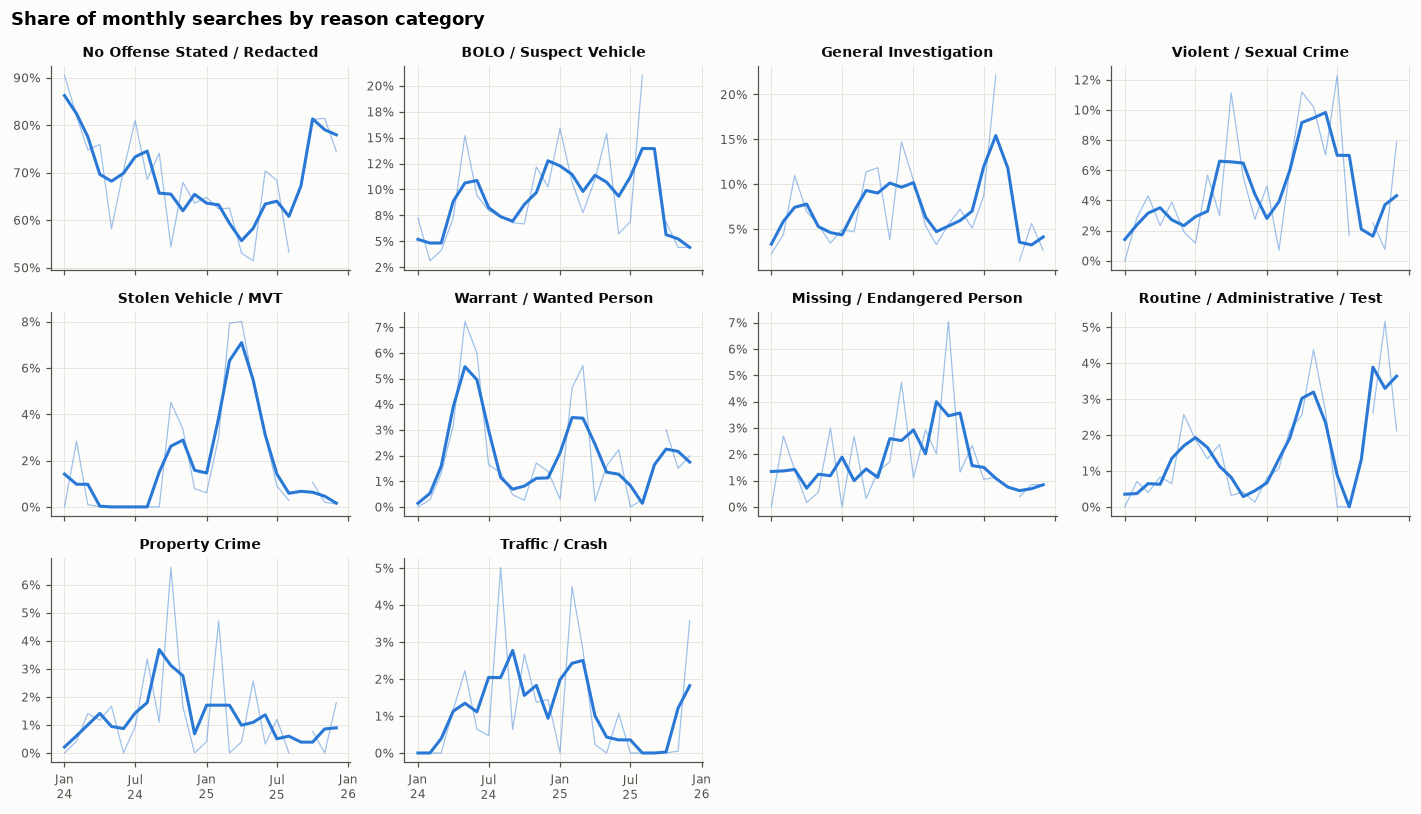

In [9]:
share = (pd.crosstab(wr["month"], wr["reason_category"], normalize="index")
           .reindex(months))
share[n_rec < MIN_N] = np.nan               # too few recorded reasons to compute a share
share = share[cat_tot.index]                         # order panels by overall size
share = share.loc[:, cat_tot / cat_tot.sum() >= 0.005]   # drop categories under 0.5% (see table above)
share_t = share.copy(); share_t.index = share_t.index.to_timestamp()

ncol = 4; nrow = int(np.ceil(share.shape[1] / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 2.5 * nrow), sharex=True)
for ax, cat in zip(axes.flat, share_t.columns):
    s = share_t[cat]
    ax.plot(s.index, s.values, color=BLUE, lw=0.8, alpha=0.45)
    ax.plot(s.index, s.rolling(3, center=True, min_periods=2).mean(), color=BLUE, lw=2)
    ax.set_title(cat, fontsize=9)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%y"))
for ax in axes.flat[share.shape[1]:]:
    ax.set_visible(False)
fig.suptitle("Share of monthly searches by reason category", fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.show()

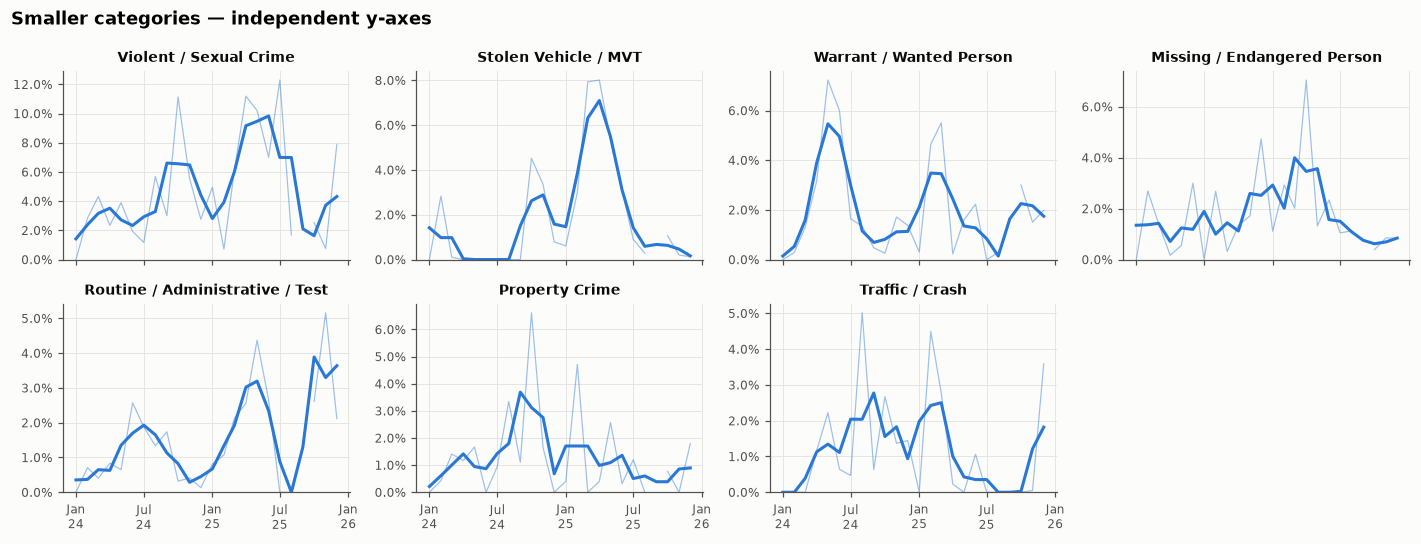

In [10]:
# Small categories are hard to read on the shared scale, so re-plot them with their own y-axes
small = [c for c in share.columns if share[c].mean() < 0.05]
assert len(small) > 0
fig, axes = plt.subplots(int(np.ceil(len(small) / 4)), 4, figsize=(13, 2.5 * int(np.ceil(len(small) / 4))), sharex=True)
for ax, cat in zip(np.ravel(axes), small):
    s = share_t[cat]
    ax.plot(s.index, s.values, color=BLUE, lw=0.8, alpha=0.45)
    ax.plot(s.index, s.rolling(3, center=True, min_periods=2).mean(), color=BLUE, lw=2)
    ax.set_title(cat, fontsize=9); ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%y"))
for ax in np.ravel(axes)[len(small):]:
    ax.set_visible(False)
fig.suptitle("Smaller categories — independent y-axes", fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.show()

### 4c. Did officers state an offense?
This tracks the share of searches whose reason maps to an actual offense category, as opposed to a bare case number, a name, an unintelligible entry, or test/admin activity. It is the clearest single **accountability trend** in the data.

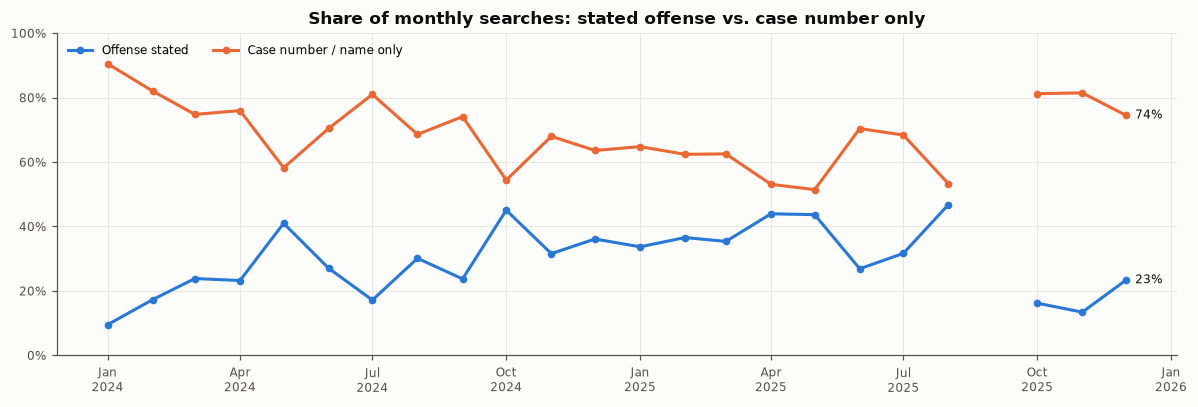

In [11]:
off = wr.groupby("month")["has_offense"].mean().reindex(months).where(n_rec >= MIN_N)
cno = (wr.assign(c=wr["reason_category"].eq("No Offense Stated / Redacted"))
         .groupby("month")["c"].mean().reindex(months).where(n_rec >= MIN_N))
off.index = off.index.to_timestamp(); cno.index = cno.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(off.index, off.values, color=BLUE, marker="o", ms=4, label="Offense stated")
ax.plot(cno.index, cno.values, color=ORANGE, marker="o", ms=4, label="Case number / name only")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_title("Share of monthly searches: stated offense vs. case number only")
for s, c in [(off, BLUE), (cno, ORANGE)]:
    ax.annotate(f"{s.dropna().iloc[-1]:.0%}", (s.dropna().index[-1], s.dropna().iloc[-1]), xytext=(6, 0), textcoords="offset points",
                fontsize=8, color=INK, va="center")
ax.legend(loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

### 4d. Period-over-period change
This compares half-year category shares. The last column, **Δ pp**, is the change in percentage points from H1 2024 to H2 2025.

In [12]:
wr["half"] = wr["search_time"].dt.year.astype(str) + "-H" + np.where(wr["search_time"].dt.month <= 6, "1", "2")
half = pd.crosstab(wr["reason_category"], wr["half"], normalize="columns") * 100
half["Δ pp (H1'24→H2'25)"] = half["2025-H2"] - half["2024-H1"]
half = half.sort_values("Δ pp (H1'24→H2'25)")
half.round(1)

half,2024-H1,2024-H2,2025-H1,2025-H2,Δ pp (H1'24→H2'25)
reason_category,,,,,
BOLO / Suspect Vehicle,8.0,9.1,11.6,6.2,-1.8
Warrant / Wanted Person,3.4,1.1,2.3,1.7,-1.8
Drug Investigation,1.8,0.1,0.1,0.1,-1.6
General Investigation,6.5,9.7,6.4,5.4,-1.1
Missing / Endangered Person,1.2,2.2,2.8,0.8,-0.4
Property Crime,1.1,2.5,1.3,0.8,-0.3
Malformed / Unintelligible,0.3,0.1,0.2,0.0,-0.3
Stolen Vehicle / MVT,0.5,2.2,4.7,0.4,-0.0
Misc / Other,0.0,0.1,0.2,0.0,0.0


In [13]:
# Same comparison, restricted to searches that stated an offense (removes the case-number-only noise)
o = wr[wr["has_offense"]]
half_off = pd.crosstab(o["reason_category"], o["half"], normalize="columns") * 100
half_off["Δ pp (H1'24→H2'25)"] = half_off["2025-H2"] - half_off["2024-H1"]
half_off.sort_values("Δ pp (H1'24→H2'25)").round(1)

half,2024-H1,2024-H2,2025-H1,2025-H2,Δ pp (H1'24→H2'25)
reason_category,,,,,
Drug Investigation,6.7,0.1,0.2,0.6,-6.1
Warrant / Wanted Person,13.0,3.2,6.2,7.9,-5.1
BOLO / Suspect Vehicle,30.4,26.5,31.0,29.7,-0.7
Missing / Endangered Person,4.5,6.3,7.6,3.8,-0.7
Property Crime,4.0,7.3,3.5,3.7,-0.3
Stolen Vehicle / MVT,1.7,6.5,12.7,2.0,0.3
General Investigation,24.7,28.2,17.1,25.9,1.2
Traffic / Crash,3.4,5.2,3.6,4.8,1.5
Violent / Sexual Crime,11.6,16.7,18.1,21.4,9.8


## 5. When searches happen

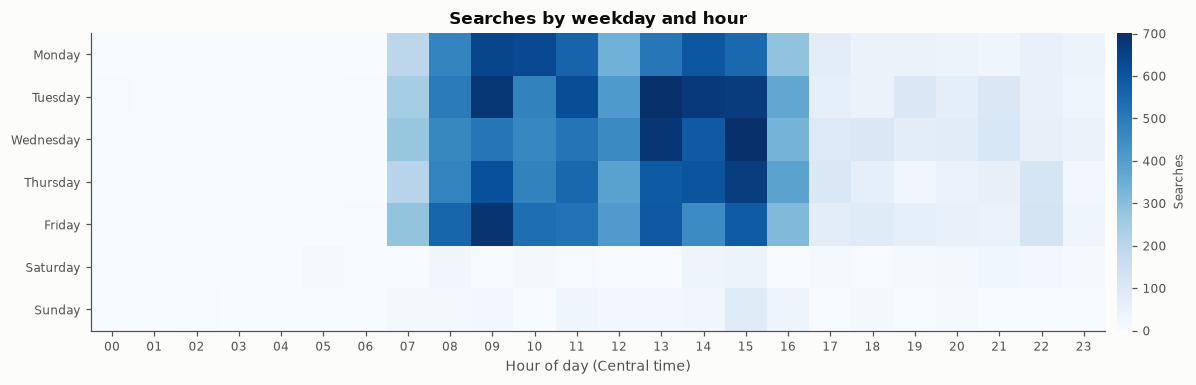

Searches between 07:00 and 16:59: 91.4%
Searches on weekends:              1.8%  (2/7 = 28.6% if uniform)


In [14]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = pd.crosstab(w["weekday"], w["hour"]).reindex(index=order, columns=range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 3.6))
im = ax.imshow(heat.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(24)); ax.set_xticklabels([f"{h:02d}" for h in range(24)])
ax.set_yticks(range(7)); ax.set_yticklabels(order)
ax.set_xlabel("Hour of day (Central time)"); ax.grid(False)
ax.set_title("Searches by weekday and hour")
cb = fig.colorbar(im, ax=ax, pad=0.01); cb.set_label("Searches", fontsize=8); cb.outline.set_visible(False)
plt.tight_layout(); plt.show()

day_share = w["hour"].between(7, 16).mean()
wkend = w["weekday"].isin(["Saturday", "Sunday"]).mean()
print(f"Searches between 07:00 and 16:59: {day_share:.1%}")
print(f"Searches on weekends:              {wkend:.1%}  (2/7 = 28.6% if uniform)")

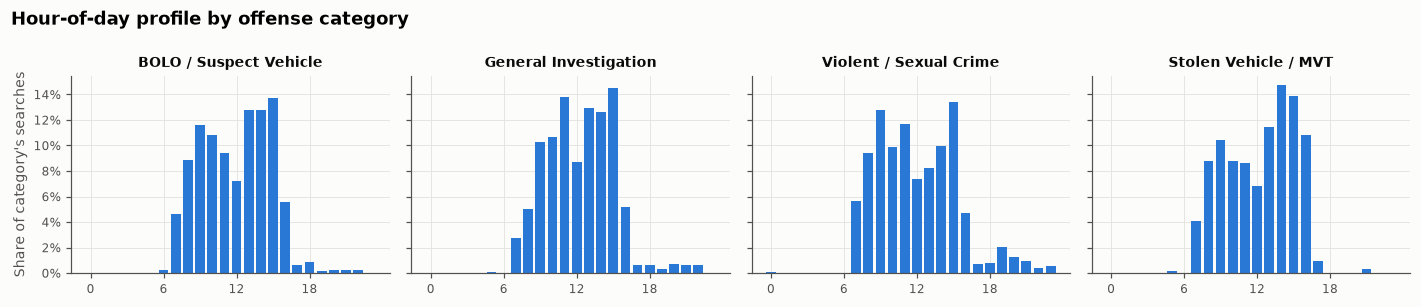

In [15]:
# Hour-of-day profile for the four largest offense categories (each normalised to its own total)
top_off = o["reason_category"].value_counts().index[:4]
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8), sharey=True)
for ax, cat in zip(axes, top_off):
    h = o.loc[o["reason_category"] == cat, "hour"].value_counts(normalize=True).reindex(range(24), fill_value=0)
    ax.bar(h.index, h.values, color=BLUE, width=0.8)
    ax.set_title(cat, fontsize=9); ax.set_xticks([0, 6, 12, 18])
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylabel("Share of category's searches")
fig.suptitle("Hour-of-day profile by offense category", fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.show()

## 6. Search scope
This section asks how far back in time each search looks and how many cameras it sweeps, and whether either is growing.

In [16]:
print("Searched time window (hours):")
print(w["window_hours"].describe(percentiles=[.25, .5, .75, .9, .99]).round(1).to_string())

bins   = [0, 1, 6, 24, 24*7, 24*31, np.inf]
labels = ["≤1h", "1–6h", "6–24h", "1–7 days", "7–31 days", ">31 days"]
w["window_bucket"] = pd.cut(w["window_hours"], bins=bins, labels=labels, include_lowest=True)
print("\nWindow-length buckets:")
print(w["window_bucket"].value_counts(normalize=True).reindex(labels).map("{:.1%}".format).to_string())

Searched time window (hours):
count    27753.0
mean       303.3
std        555.3
min          0.0
25%         24.0
50%        168.0
75%        720.0
90%        720.0
99%       1355.0
max      26280.0

Window-length buckets:
window_bucket
≤1h           8.0%
1–6h          7.9%
6–24h        18.9%
1–7 days     26.5%
7–31 days    35.0%
>31 days      3.6%


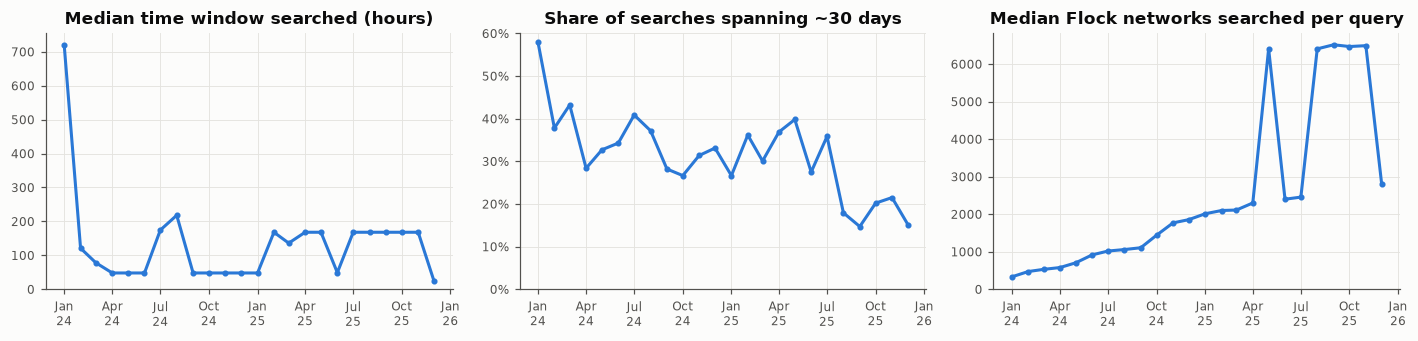

Caveat: device/network counts are reported differently across source audits (some redact devices,
some report national vs. shared-network scope), so jumps in the right panel can be source-driven.


In [17]:
scope = w.groupby("month").agg(median_window_h=("window_hours", "median"),
                               median_networks=("total_networks_searched", "median"),
                               share_30d=("window_hours", lambda s: (s >= 24*28).mean())).reindex(months)
scope.index = scope.index.to_timestamp()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].plot(scope.index, scope["median_window_h"], color=BLUE, marker="o", ms=3)
axes[0].set_title("Median time window searched (hours)")
axes[1].plot(scope.index, scope["share_30d"], color=BLUE, marker="o", ms=3)
axes[1].set_title("Share of searches spanning ~30 days")
axes[1].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[2].plot(scope.index, scope["median_networks"], color=BLUE, marker="o", ms=3)
axes[2].set_title("Median Flock networks searched per query")
for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%y")); ax.set_ylim(bottom=0)
plt.tight_layout(); plt.show()
print("Caveat: device/network counts are reported differently across source audits (some redact devices,")
print("some report national vs. shared-network scope), so jumps in the right panel can be source-driven.")

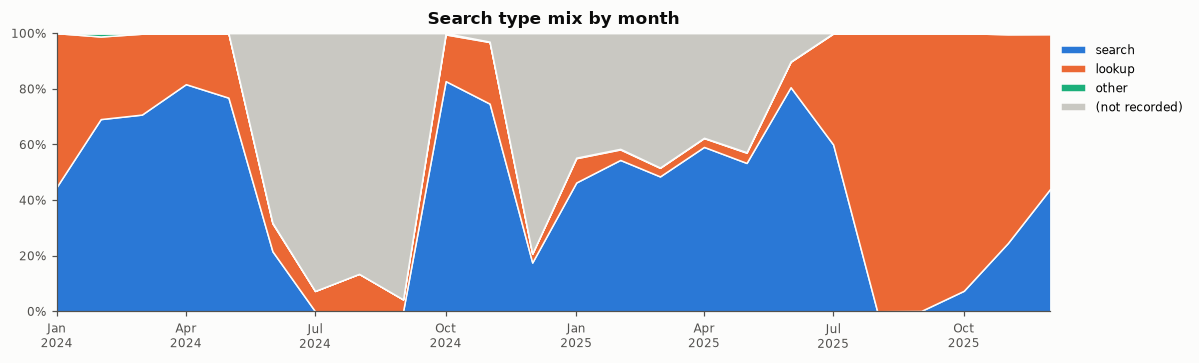

In [18]:
# Search type over time (the field is blank on older audits)
st = w["search_type"].fillna("(not recorded)")
st = st.where(st.isin(["search", "lookup", "(not recorded)"]), "other")
st_m = pd.crosstab(w["month"], st, normalize="index").reindex(months, fill_value=0)
st_m.index = st_m.index.to_timestamp()
cols = ["search", "lookup", "other", "(not recorded)"]
colors = [BLUE, ORANGE, AQUA, "#c9c8c2"]
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.stackplot(st_m.index, [st_m.get(c, 0) for c in cols], labels=cols, colors=colors,
             edgecolor="#fcfcfb", linewidth=1)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_ylim(0, 1); ax.margins(x=0)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_title("Search type mix by month"); ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

## 7. User accounts and case-number-only reasons
Officer names in the audits are already truncated (e.g. `D. Joh`). This section looks at how concentrated search activity is and whether the **case-number-only** pattern comes from a few accounts or is department-wide. That answers the open question in `norm_template.ipynb` about why Murfreesboro has so many "No Offense Stated / Redacted" rows.

In [19]:
acct = wr.assign(user=wr["name"].fillna("(name redacted)"))
acct_tbl = (acct.groupby("user")
                .agg(searches=("id", "size"),
                     case_no_only=("reason_category", lambda s: (s == "No Offense Stated / Redacted").mean()),
                     offense_stated=("has_offense", "mean"),
                     first=("search_time", "min"), last=("search_time", "max"))
                .sort_values("searches", ascending=False))
acct_tbl["share_of_all"] = acct_tbl["searches"] / acct_tbl["searches"].sum()
acct_tbl["first"] = acct_tbl["first"].dt.date; acct_tbl["last"] = acct_tbl["last"].dt.date
acct_tbl.style.format({"case_no_only": "{:.0%}", "offense_stated": "{:.0%}", "share_of_all": "{:.1%}"})

,searches,case_no_only,offense_stated,first,last,share_of_all
user,,,,,,
D. Joh,14156,64%,34%,2024-01-04,2025-12-11,55.8%
M. Hic,2790,57%,42%,2024-09-30,2025-12-10,11.0%
(name redacted),2375,65%,33%,2024-08-02,2025-12-31,9.4%
C. Tho,1809,78%,21%,2024-02-08,2025-12-10,7.1%
R. Law,1501,65%,34%,2024-01-05,2025-11-17,5.9%
B. Arn,917,93%,4%,2025-10-10,2025-12-10,3.6%
W. Chi,767,90%,10%,2025-10-10,2025-12-10,3.0%
K. Gag,442,87%,5%,2025-11-10,2025-12-11,1.7%
N. Fro,384,89%,10%,2024-02-01,2025-12-01,1.5%


In [20]:
ido = wr[wr["reason_category"] == "No Offense Stated / Redacted"]["reason_normalized"].fillna("")
CASE = r"(?:mp+a+t?[-\s]?\d{2}[-\s]?\d+|\d{2}[-\s]\d{3,}[a-z]?)"

def id_kind(s):                                   # mutually exclusive buckets
    if re.fullmatch(rf"\s*{CASE}\s*", s):        return "Case number only"
    if re.search(CASE, s):                         return "Case number + name/text"
    if not re.search(r"\d", s):                  return "Name / initials only"
    return "Other identifier (plate, badge #, etc.)"

kinds = ido.apply(id_kind).value_counts()
print(f"'No Offense Stated / Redacted' searches in window: {len(ido):,}\n")
print(pd.DataFrame({"searches": kinds, "share": (kinds / kinds.sum()).map("{:.1%}".format)}).to_string())

'No Offense Stated / Redacted' searches in window: 17,009

                                         searches  share
reason_normalized                                       
Case number only                            14308  84.1%
Name / initials only                         1257   7.4%
Case number + name/text                      1144   6.7%
Other identifier (plate, badge #, etc.)       300   1.8%


## 8. Reason vocabulary
These are the most common words in the reason field after stripping case numbers and plate-like tokens, compared between 2024 and 2025.

In [21]:
STOP = {"the", "a", "of", "and", "to", "in", "for", "on", "at", "with", "from", "by", "or", "is", "veh", "vehicle"}

def tokens(s):
    s = re.sub(r"\bmp+a+t?[-\s]?\d{2}[-\s]?\d+|\b\d{2}[-\s]\d{3,}|\b\d+\b", " ", s or "")
    return [t for t in re.findall(r"[a-z][a-z']+", s) if t not in STOP and len(t) > 2]

wr["tokens"] = wr["reason_normalized"].fillna("").apply(tokens)
yr = wr["search_time"].dt.year
counts = {y: wr.loc[yr == y, "tokens"].explode().dropna().value_counts() for y in (2024, 2025)}
n_by_year = yr.value_counts()

top = counts[2024].head(20).index.union(counts[2025].head(20).index)
vocab = pd.DataFrame({f"{y} (per 1k searches)": (counts[y].reindex(top, fill_value=0) / n_by_year[y] * 1000).round(1)
                      for y in (2024, 2025)})
vocab["change"] = vocab.iloc[:, 1] - vocab.iloc[:, 0]
vocab.sort_values("change")    # bottom = terms rising in 2025, top = terms fading

,2024 (per 1k searches),2025 (per 1k searches),change
tokens,,,
det,41.8,19.6,-22.2
susp,19.7,6.2,-13.5
sgt,15.4,2.4,-13.0
thefts,7.7,0.0,-7.7
tag,9.4,2.8,-6.6
case,9.0,2.6,-6.4
flg,8.6,2.4,-6.2
stolen,12.7,6.6,-6.1
alert,20.4,16.8,-3.6


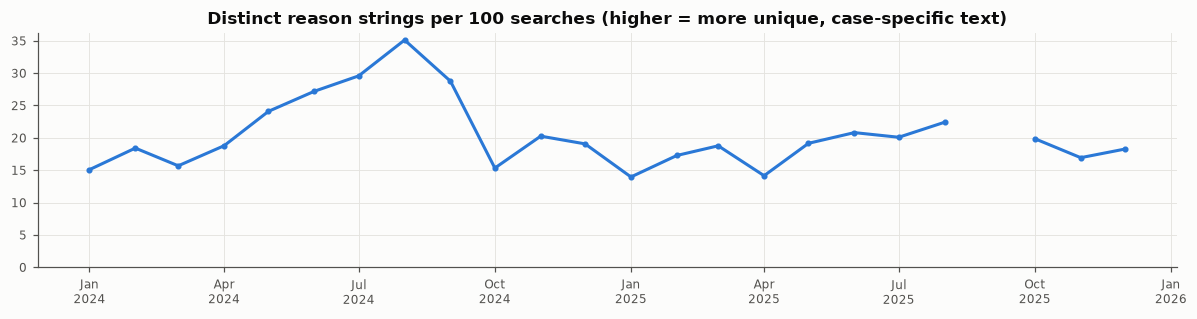

In [22]:
# Vocabulary richness: how many distinct reason strings are used per 100 searches?
div = wr.groupby("month").agg(searches=("id", "size"), distinct=("reason_normalized", "nunique")).reindex(months)
div["distinct_per_100"] = (div["distinct"] / div["searches"] * 100).where(n_rec >= MIN_N)
div.index = div.index.to_timestamp()
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(div.index, div["distinct_per_100"], color=BLUE, marker="o", ms=3)
ax.set_title("Distinct reason strings per 100 searches (higher = more unique, case-specific text)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y")); ax.set_ylim(bottom=0)
plt.tight_layout(); plt.show()

## 9. Export tables for the cross-city comparison

In [23]:
monthly_cat = pd.crosstab(w["month"], w["reason_category"]).reindex(months, fill_value=0)
monthly_cat.to_csv(f"{OUT_DIR}/monthly_category_counts.csv")
share.to_csv(f"{OUT_DIR}/monthly_category_share.csv")
half.round(2).to_csv(f"{OUT_DIR}/halfyear_category_share.csv")
heat.to_csv(f"{OUT_DIR}/weekday_hour_counts.csv")
coverage.to_csv(f"{OUT_DIR}/coverage_by_month.csv")
df.drop(columns=["tokens"], errors="ignore").to_csv(f"{OUT_DIR}/Murfreesboro_deduped.csv", index=False)
print("Wrote:", *sorted(os.listdir(OUT_DIR)), sep="\n  ")

Wrote:
  Murfreesboro_deduped.csv
  coverage_by_month.csv
  halfyear_category_share.csv
  monthly_category_counts.csv
  monthly_category_share.csv
  weekday_hour_counts.csv


## 10. Findings (Murfreesboro PD, Jan 2024 – Dec 2025)

**Data quality**
- **40.7% of raw rows are duplicates.** The same search shows up in several source audits. After dedup: 47,501 rows → **28,183 unique searches**. The cross-city pivot in `norm_template.ipynb` should be rebuilt on deduplicated data before comparing cities.
- **8.5% of searches have no reason because their source audit omitted the field.** This is mostly Dunwoody GA's audits, including almost all of Sep 2025. Previously these were counted as "Malformed / Unintelligible". They are now separated out, which drops "Malformed" from ~9% to 0.1%.
- **Volume follows coverage.** Monthly search counts correlate with the number of source audits available (r ≈ 0.66), so the +57% volume increase from 2024 to 2025 can't be read as a real increase in searching. Share-based trends are the reliable ones.

**Why Murfreesboro is so heavy on "No Offense Stated"** (answers the note in the template)
- 67% of searches with a recorded reason give no offense. Of those, **84% are a bare case number** (`MPPAT-YY-NNNNNNN` or `YY-NNNN`), 7% are a name only, and 7% are a case number plus a name.
- The practice is **department-wide, not one or two accounts**: every account uses case-number-only reasons for 54–93% of its searches.
- The trend improved through mid-2025 and then reversed. Offense-stated searches rose from ~10% (Jan 2024) to ~45% (Aug 2025), then fell back to ~13–23% in Oct–Dec 2025.

**Category trends (searches with a stated offense only)**
- **Violent / Sexual Crime rose** from 11.6% (H1 2024) to 21.4% (H2 2025), the largest gain. ICAC appears as a new term in 2025.
- **Drug Investigation nearly vanished** after H1 2024 (6.7% → <1%). **Warrant / Wanted** fell from 13.0% to 7.9%.
- **Stolen Vehicle spiked in H1 2025** (12.7%) and returned to baseline. "VIN" appears as a new 2025 term.
- BOLO / Suspect Vehicle was steady at ~30%. "ATL" (attempt to locate) usage more than quadrupled per search in 2025.

**When and how**
- **91% of searches happen 07:00–16:59 Central and only 1.8% on weekends.** That pattern points to investigative/detective-unit use during office hours, not patrol.
- **One account (`D. Joh`) makes 56% of all searches**, and the top two make 67%.
- Search windows are long: the median search looks back 7 days, and 39% look back more than 7 days. The share of ~30-day lookbacks fell from ~40% to ~15–20% in late 2025.

**Caveats:** shares for months with few records are noisy. Network and device counts are reported inconsistently across source audits. Categories depend on the shared regex mapping in `norm_template.ipynb`.
